# Life Expectancy Analysis & Prediction
### End-to-end data science workflow: from raw WHO data to a tuned predictive model

**Contents**
1. Problem Statement
2. Proposed Solution
3. Importing Libraries
4. Understanding the Dataset
5. Data Cleaning
6. Exploratory Data Analysis (EDA)
7. Data Visualization
8. Feature Engineering
9. Model Building
10. Model Evaluation
11. Hyperparameter Tuning
12. Final Model Evaluation & Interpretation
13. Conclusion & Recommendations

## 1. Problem Statement

Life expectancy at birth is one of the most widely used summary indicators of a population's health and development. Gaps of 30 years or more still separate the longest-living and shortest-living countries, and governments, NGOs and funders have to decide where limited health budgets will have the most impact.

This project uses the WHO / UN life expectancy dataset (193 countries, 2000-2015) and tries to answer three questions:

1. **What drives life expectancy?** Which immunization, mortality, economic, social and lifestyle factors are most strongly associated with it?
2. **Do developed and developing countries differ systematically**, and has the gap narrowed over time?
3. **Can we predict a country's life expectancy** from these indicators accurately enough to be useful, including for countries the model has never seen?

**Type of problem:** supervised learning, *regression* (target: `Life expectancy`, in years).

## 2. Proposed Solution

| Step | Approach |
|---|---|
| Data understanding | Inspect structure, types, ranges, coverage (country x year panel) and data quality |
| Data cleaning | Standardise column names, validate values against domain knowledge, handle missing values per country over time, document (not blindly remove) outliers |
| EDA & visualization | Distributions, correlations, statistical tests, multicollinearity (VIF), time trends, country rankings |
| Feature engineering | Log-transform skewed variables, combine redundant ones (vaccination coverage, thinness), add interaction/time features |
| Modeling | Compare a naive baseline, regularised linear models and tree ensembles (Random Forest, Gradient Boosting, XGBoost) |
| Validation | **Group-aware** splitting: all rows of a country stay in the same fold, so scores reflect performance on *unseen countries* and avoid leakage |
| Tuning | Randomised search with grouped cross-validation on the strongest models |
| Interpretation | Permutation importance, partial dependence, linear coefficients, error analysis |

## 3. Importing Libraries

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from xgboost import XGBRegressor
import joblib

## 4. Understanding the Dataset

The file is a **panel dataset**: one row per country per year (2000-2015). Place `Life_Expectancy_Data.csv` in the same folder as this notebook (the code also falls back to the upload location used when this notebook was created).

### 4.1 Source and background
The data comes from the **Global Health Observatory (GHO)** repository of the **World Health Organization (WHO)**, which tracks health status and related factors for all countries and makes the data public for health analysis. Life expectancy and health factors come from WHO, and the matching economic data comes from the **United Nations**.

- Of all health-related categories, only the most representative factors were kept.
- Only **2000-2015** is covered, because the last 15 years saw major improvements in mortality, especially in developing nations, compared with the previous 30 years.
- The separate source files were merged into one dataset of **22 columns and 2,938 rows (20 predictor variables)**.
- Because the data is from WHO, the compilers found no evident errors. Missing values (checked with R's `missmap`) were mostly in **population, Hepatitis B and GDP**, mainly for lesser-known countries such as Vanuatu, Tonga, Togo and Cabo Verde. The compilers noted these were hard to complete and excluded such countries from their final model dataset.

**Predictors fall into four broad categories** (the category descriptions are from the source; the assignment of each column below is our reading):

| Category | Columns |
|---|---|
| Immunization-related | Hepatitis B, Polio, Diphtheria |
| Mortality | Adult Mortality, infant deaths, under-five deaths, HIV/AIDS, Measles |
| Economic | GDP, percentage expenditure, Total expenditure, Income composition of resources |
| Social | Schooling, Alcohol, BMI, thinness (1-19 and 5-9 years), Population, Status, Year |

> **Note for this notebook:** the file we received still contains all 193 countries: 183 have the full 16 years (2,928 rows) and 10 appear in a single row only (2,938 rows in total). Those 10 single rows have no life-expectancy value, so removing rows without a target leaves **183 countries (2,928 rows)**, and and we handle the remaining gaps by within-country interpolation and training-only median imputation (Section 5) rather than excluding further countries. Mortality columns are partly outcomes of the same health system as life expectancy, which is why Section 12.5 also tests a model without them.


In [2]:
df = pd.read_csv("Life Expectancy Data.csv")

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

df.head()

Rows: 2,938 | Columns: 22


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

**Data dictionary** (as documented for the WHO Global Health Observatory / UN data used in this dataset):

| Column | Meaning |
|---|---|
| Country, Year | Panel identifiers |
| Status | Developed or Developing |
| **Life expectancy** | **Target:** life expectancy at birth (years) |
| Adult Mortality | Adult deaths per 1,000 population (both sexes, ages 15-60) |
| infant deaths | Infant deaths per 1,000 population |
| under-five deaths | Under-five deaths per 1,000 population |
| Alcohol | Recorded alcohol consumption per capita (litres of pure alcohol, 15+) |
| percentage expenditure | Health expenditure as a % of GDP per capita |
| Total expenditure | Government health expenditure as a % of total government expenditure |
| Hepatitis B, Polio, Diphtheria | Immunization coverage among 1-year-olds (%) |
| Measles | Reported cases per 1,000 population |
| BMI | Average body mass index of the population |
| HIV/AIDS | Deaths per 1,000 live births (ages 0-4) due to HIV/AIDS |
| GDP | Gross domestic product per capita (USD) |
| Population | Population of the country |
| thinness 1-19 years / 5-9 years | Prevalence of thinness among the age groups (%) |
| Income composition of resources | Human Development Index in terms of income composition (0-1) |
| Schooling | Average years of schooling |

In [4]:
print("Countries:", df["Country"].nunique())
print("Years:", df["Year"].min(), "-", df["Year"].max())
print("\nRows per country (panel completeness):")
print(df.groupby("Country").size().value_counts().rename("n_countries").rename_axis("rows_per_country"))
print("\nStatus split (rows):")
print(df["Status"].value_counts())
print("\nStatus split (countries):")
print(df.groupby("Country")["Status"].nunique().value_counts().rename("n_status_values_per_country"))

Countries: 193
Years: 2000 - 2015

Rows per country (panel completeness):
rows_per_country
16    183
1      10
Name: n_countries, dtype: int64

Status split (rows):
Status
Developing    2426
Developed      512
Name: count, dtype: int64

Status split (countries):
Status
1    193
Name: n_status_values_per_country, dtype: int64


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,2938.0,2.007519e+03,4.613841e+00,2000.00000,2004.000000,2.008000e+03,2.012000e+03,2.015000e+03
Life expectancy,2928.0,6.922493e+01,9.523867e+00,36.30000,63.100000,7.210000e+01,7.570000e+01,8.900000e+01
Adult Mortality,2928.0,1.647964e+02,1.242921e+02,1.00000,74.000000,1.440000e+02,2.280000e+02,7.230000e+02
infant deaths,2938.0,3.030395e+01,1.179265e+02,0.00000,0.000000,3.000000e+00,2.200000e+01,1.800000e+03
Alcohol,2744.0,4.602861e+00,4.052413e+00,0.01000,0.877500,3.755000e+00,7.702500e+00,1.787000e+01
percentage expenditure,2938.0,7.382513e+02,1.987915e+03,0.00000,4.685343,6.491291e+01,4.415341e+02,1.947991e+04
Hepatitis B,2385.0,8.094046e+01,2.507002e+01,1.00000,77.000000,9.200000e+01,9.700000e+01,9.900000e+01
Measles,2938.0,2.419592e+03,1.146727e+04,0.00000,0.000000,1.700000e+01,3.602500e+02,2.121830e+05
BMI,2904.0,3.832125e+01,2.004403e+01,1.00000,19.300000,4.350000e+01,5.620000e+01,8.730000e+01
under-five deaths,2938.0,4.203574e+01,1.604455e+02,0.00000,0.000000,4.000000e+00,2.800000e+01,2.500000e+03


**First impressions**
- The dataset is a (nearly) balanced panel, so each country contributes many correlated rows. This matters for validation: a random row-wise split would put the same country in both train and test and give over-optimistic scores.
- Column names contain stray spaces (e.g. `" BMI"`, `" HIV/AIDS"`, `" thinness  1-19 years"`) and inconsistent casing.
- Several columns have missing values, and some ranges look implausible (e.g. `BMI` far above 60, zero values for `Schooling`).
- Features such as `infant deaths`, `Measles` and `Population` are on very different, highly skewed scales.

## 5. Data Cleaning

Cleaning follows a documented, reproducible order: (1) standardise names, (2) remove duplicates and fix types, (3) validate values, (4) handle missing values, (5) review outliers.

### 5.1 Standardise column names and text fields

In [6]:
def to_snake(col):
    return re.sub(r"[^0-9a-zA-Z]+", "_", col.strip()).strip("_").lower()

df.columns = [to_snake(c) for c in df.columns]
df["country"] = df["country"].str.strip()
df["status"] = df["status"].str.strip()
print(list(df.columns))

['country', 'year', 'status', 'life_expectancy', 'adult_mortality', 'infant_deaths', 'alcohol', 'percentage_expenditure', 'hepatitis_b', 'measles', 'bmi', 'under_five_deaths', 'polio', 'total_expenditure', 'diphtheria', 'hiv_aids', 'gdp', 'population', 'thinness_1_19_years', 'thinness_5_9_years', 'income_composition_of_resources', 'schooling']


### 5.2 Duplicates, data types and categorical consistency

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate country-year pairs:", df.duplicated(subset=["country", "year"]).sum())
print("Status values:", df["status"].unique())
df["status"] = df["status"].astype("category")
df = df.sort_values(["country", "year"]).reset_index(drop=True)

Duplicate rows: 0
Duplicate country-year pairs: 0
Status values: ['Developing' 'Developed']


### 5.3 Missing values

,missing_count,missing_pct
population,652,22.191967
hepatitis_b,553,18.822328
gdp,448,15.248468
total_expenditure,226,7.692308
alcohol,194,6.603131
income_composition_of_resources,167,5.684139
schooling,163,5.547992
thinness_5_9_years,34,1.157250
thinness_1_19_years,34,1.157250
bmi,34,1.157250


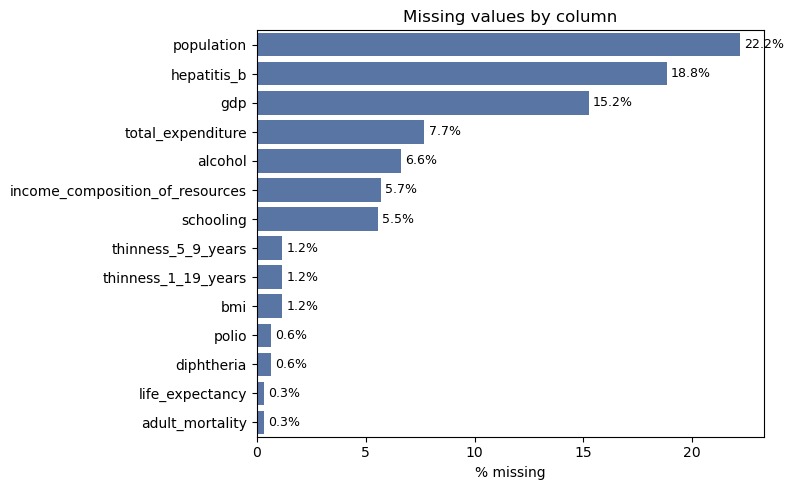

In [8]:
missing = (df.isna().sum().to_frame("missing_count")
             .assign(missing_pct=lambda d: d["missing_count"] / len(df) * 100)
             .query("missing_count > 0").sort_values("missing_pct", ascending=False))
display(missing)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=missing["missing_pct"], y=missing.index, ax=ax, color="#4C72B0")
ax.set_xlabel("% missing"); ax.set_ylabel(""); ax.set_title("Missing values by column")
for i, v in enumerate(missing["missing_pct"]):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

Population (22%), Hepatitis B (19%) and GDP (15%) have the most gaps. Missingness is *structured*: it often covers whole countries or whole stretches of years, so a country-level approach is more appropriate than a global mean.

### 5.4 Domain validation of values
Before imputing, physically impossible or suspicious values are converted to missing so they are treated consistently. We first count how many rows each rule affects.

In [9]:
checks = {
    "bmi outside plausible national mean range [10, 50]": ((df["bmi"] < 10) | (df["bmi"] > 50)).sum(),
    "adult_mortality < 10 per 1,000 (e.g. Afghanistan 2002 = 3 between 316 and 295)": (df["adult_mortality"] < 10).sum(),
    "income_composition_of_resources == 0 (HDI of 0 is not real)": (df["income_composition_of_resources"] == 0).sum(),
    "schooling == 0": (df["schooling"] == 0).sum(),
    "coverage (hep B / polio / diphtheria) outside [0, 100]": ((df[["hepatitis_b","polio","diphtheria"]] > 100) | (df[["hepatitis_b","polio","diphtheria"]] < 0)).sum().sum(),
    "life_expectancy outside [30, 95]": ((df["life_expectancy"] < 30) | (df["life_expectancy"] > 95)).sum(),
    "negative values in any numeric column": (df.select_dtypes("number") < 0).sum().sum(),
}
pd.Series(checks, name="rows_affected").to_frame()

,rows_affected
"bmi outside plausible national mean range [10, 50]",1422
"adult_mortality < 10 per 1,000 (e.g. Afghanistan 2002 = 3 between 316 and 295)",86
income_composition_of_resources == 0 (HDI of 0 is not real),130
schooling == 0,28
"coverage (hep B / polio / diphtheria) outside [0, 100]",0
"life_expectancy outside [30, 95]",0
negative values in any numeric column,0


In [10]:
bmi_invalid_pct = ((df["bmi"] < 10) | (df["bmi"] > 50)).mean() * 100
print(f"BMI: {bmi_invalid_pct:.0f}% of values are outside the plausible range")

# Apply the rules: invalid -> NaN (to be imputed in the next step)
df.loc[df["adult_mortality"] < 10, "adult_mortality"] = np.nan
df.loc[df["income_composition_of_resources"] == 0, "income_composition_of_resources"] = np.nan
df.loc[df["schooling"] == 0, "schooling"] = np.nan

BMI: 48% of values are outside the plausible range


**Decision on `bmi`:** nearly half of its values are physically implausible for a national average (many above 50, some below 10), so the column is unreliable as a whole. Imputing roughly 48% of a feature would mostly fabricate data, so **`bmi` is dropped** rather than repaired. The other rules affect a small share of rows (adult mortality, HDI/schooling zeros) and are set to missing for imputation.

> Not every glitch can be caught by a range rule (e.g. some single-year jumps in vaccination or thinness values for a country). These are left as they are and are one reason we favour models robust to noise.

### 5.5 Treating missing values
1. **Rows with no target** (`life_expectancy` missing) cannot be used for supervised learning and are dropped.
2. **Within-country linear interpolation over time** is used for the features: a country's schooling, GDP or immunization rate changes smoothly, so its own neighbouring years are a far better estimate than a global average. It only uses values from the *same country*, so no information leaks between countries.
3. Whatever remains (countries with *no* observation of a feature) is imputed with the **median inside the modeling pipeline, fitted on training data only**, to prevent leakage.

In [11]:
df = df.drop(columns="bmi")
n_before = len(df)
df = df.dropna(subset=["life_expectancy"]).reset_index(drop=True)
print(f"Dropped {n_before - len(df)} rows with missing target. Remaining: {len(df):,}")

feature_cols = [c for c in df.columns if c not in ["country", "year", "status", "life_expectancy"]]
for c in feature_cols:
    df[c] = df.groupby("country", observed=True)[c].transform(lambda s: s.interpolate(method="linear", limit_direction="both"))

remaining = df[feature_cols].isna().sum()
print("\nMissing after within-country interpolation:")
display(remaining[remaining > 0].to_frame("missing_count").assign(pct=lambda d: d["missing_count"]/len(df)*100))
print("Countries still missing at least one feature:", df.loc[df[feature_cols].isna().any(axis=1), "country"].nunique())

Dropped 10 rows with missing target. Remaining: 2,928

Missing after within-country interpolation:


,missing_count,pct
alcohol,16,0.546448
hepatitis_b,144,4.918033
total_expenditure,32,1.092896
gdp,400,13.661202
population,640,21.857923
thinness_1_19_years,32,1.092896
thinness_5_9_years,32,1.092896
income_composition_of_resources,160,5.464481
schooling,160,5.464481


Countries still missing at least one feature: 50


Countries still missing at least one feature: 50


### 5.6 Outlier review

In [12]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({"n_outliers_IQR": {c: iqr_outliers(df[c].dropna()) for c in ["life_expectancy"] + feature_cols}})
out["pct"] = out["n_outliers_IQR"] / len(df) * 100
out.sort_values("pct", ascending=False)

,n_outliers_IQR,pct
hiv_aids,542,18.510929
measles,542,18.510929
under_five_deaths,394,13.456284
percentage_expenditure,388,13.251366
gdp,365,12.465847
infant_deaths,315,10.758197
diphtheria,303,10.348361
population,294,10.040984
hepatitis_b,279,9.528689
polio,259,8.845628


**Decision: outliers are kept, not deleted.** Most of them are genuine, not errors. Examples are India's and China's populations, countries with extreme HIV/AIDS burdens, and very high GDP per capita in small wealthy economies. Removing them would erase exactly the countries a health analysis most needs to understand. Instead they are handled in the feature engineering step (log transforms) and by using models that are robust to extreme values (tree ensembles).

In [13]:
df.to_csv("life_expectancy_cleaned.csv", index=False)
print("Cleaned shape:", df.shape)
df.head()

Cleaned shape: (2928, 21)


,country,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,percentage_expenditure,hepatitis_b,measles,...,polio,total_expenditure,diphtheria,hiv_aids,gdp,population,thinness_1_19_years,thinness_5_9_years,income_composition_of_resources,schooling
0,Afghanistan,2000,Developing,54.8,321.0,88,0.01,10.424960,62.0,6532,...,24.0,8.20,24.0,0.1,114.560000,293756.0,2.3,2.5,0.338,5.5
1,Afghanistan,2001,Developing,55.3,316.0,88,0.01,10.574728,63.0,8762,...,35.0,7.80,33.0,0.1,117.496980,2966463.0,2.1,2.4,0.340,5.9
2,Afghanistan,2002,Developing,56.2,305.5,88,0.01,16.887351,64.0,2486,...,36.0,7.76,36.0,0.1,187.845950,21979923.0,19.9,2.2,0.341,6.2
3,Afghanistan,2003,Developing,56.7,295.0,87,0.01,11.089053,65.0,798,...,41.0,8.82,41.0,0.1,198.728544,2364851.0,19.7,19.9,0.373,6.5
4,Afghanistan,2004,Developing,57.0,293.0,87,0.02,15.296066,67.0,466,...,5.0,8.79,5.0,0.1,219.141353,24118979.0,19.5,19.7,0.381,6.8


## 6. Exploratory Data Analysis (EDA)
### 6.1 Target variable

                  count       mean       std   min   25%   50%   75%   max
life_expectancy  2928.0  69.224932  9.523867  36.3  63.1  72.1  75.7  89.0
Skewness: -0.64 | Kurtosis: -0.23


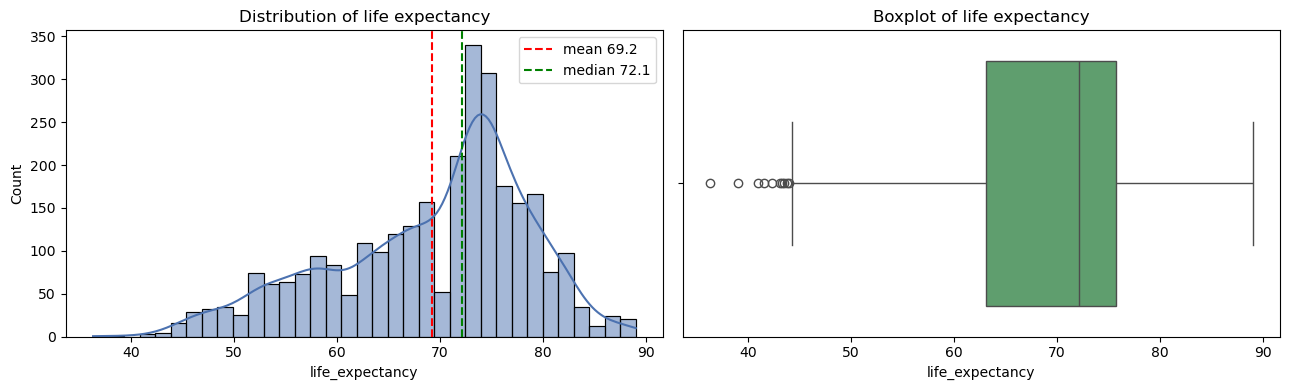

In [14]:
y = df["life_expectancy"]
print(y.describe().to_frame().T)
print(f"Skewness: {y.skew():.2f} | Kurtosis: {y.kurt():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y, kde=True, bins=35, ax=axes[0], color="#4C72B0")
axes[0].axvline(y.mean(), color="red", ls="--", label=f"mean {y.mean():.1f}")
axes[0].axvline(y.median(), color="green", ls="--", label=f"median {y.median():.1f}")
axes[0].legend(); axes[0].set_title("Distribution of life expectancy")
sns.boxplot(x=y, ax=axes[1], color="#55A868"); axes[1].set_title("Boxplot of life expectancy")
plt.tight_layout(); plt.show()

Life expectancy is **left-skewed** (a long tail of low values from low-income country-years), with the bulk between roughly 63 and 76 years. No transformation of the target is needed for tree models, and the skew is moderate for linear ones.

### 6.2 Distribution of the numeric features

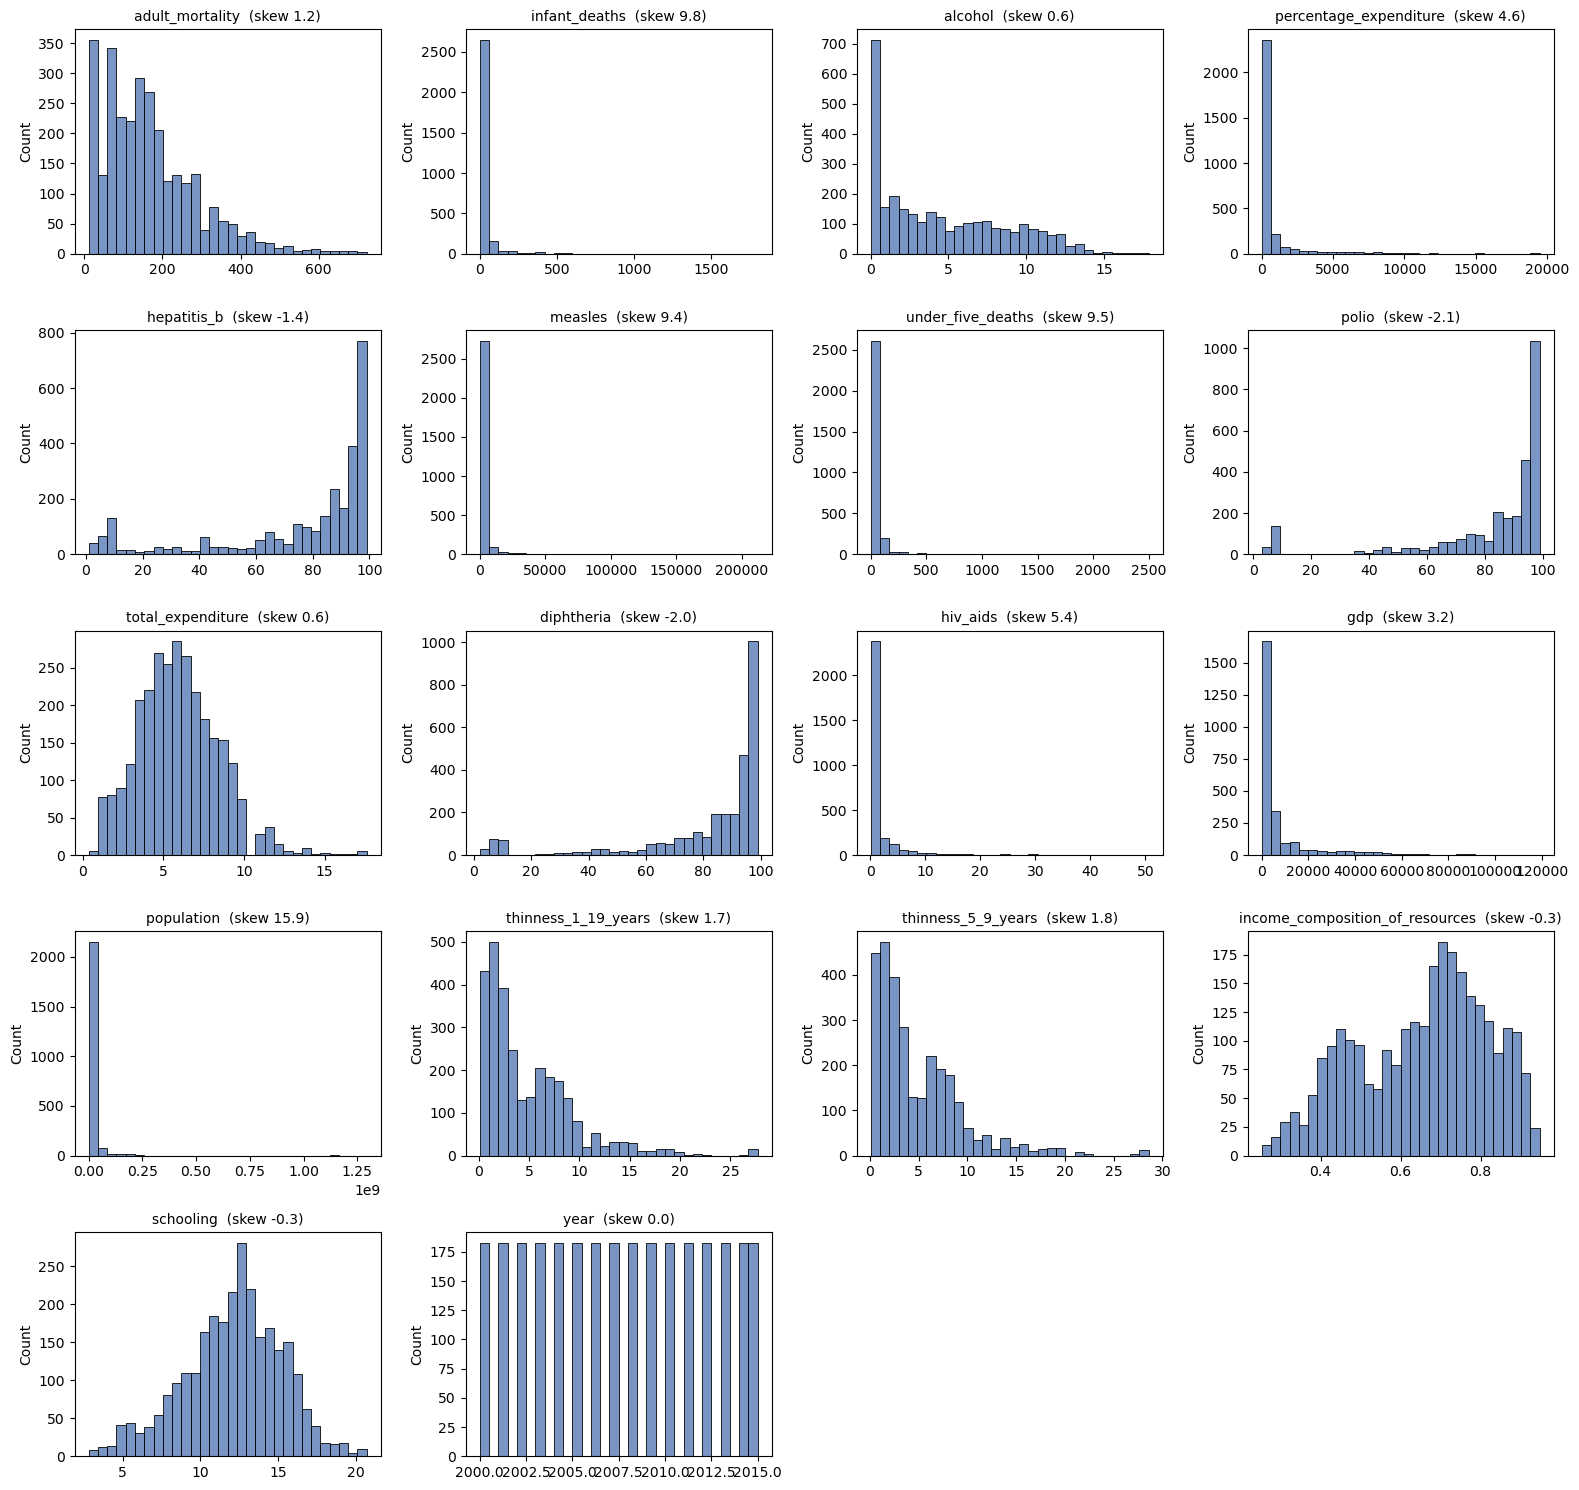

Highly skewed features (|skew| > 1):
population                15.92
infant_deaths              9.77
under_five_deaths          9.48
measles                    9.43
hiv_aids                   5.39
percentage_expenditure     4.64
gdp                        3.23
thinness_5_9_years         1.78
thinness_1_19_years        1.71
adult_mortality            1.22
hepatitis_b               -1.41
diphtheria                -2.04
polio                     -2.07


In [15]:
num_feats = feature_cols + ["year"]
n = len(num_feats); ncols = 4; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
for ax, c in zip(axes.ravel(), num_feats):
    sns.histplot(df[c], bins=30, kde=False, ax=ax, color="#4C72B0")
    ax.set_title(f"{c}  (skew {df[c].skew():.1f})", fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

skew = df[feature_cols].skew().sort_values(ascending=False)
print("Highly skewed features (|skew| > 1):")
print(skew[skew.abs() > 1].round(2).to_string())

Population, deaths, measles, HIV/AIDS, GDP and health expenditure are strongly right-skewed (long tail of very large values). These will be log-transformed during feature engineering. Immunization coverage is left-skewed (most countries cluster near 90-99%).

### 6.3 Developed vs developing countries

C:\Users\SKYTECH\AppData\Local\Temp\ipykernel_11040\962863243.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="status", ax=axes[0], palette="deep"); axes[0].set_title("Rows by development status")
C:\Users\SKYTECH\AppData\Local\Temp\ipykernel_11040\962863243.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="status", y="life_expectancy", ax=axes[1], palette="deep"); axes[1].set_title("Life expectancy by status")


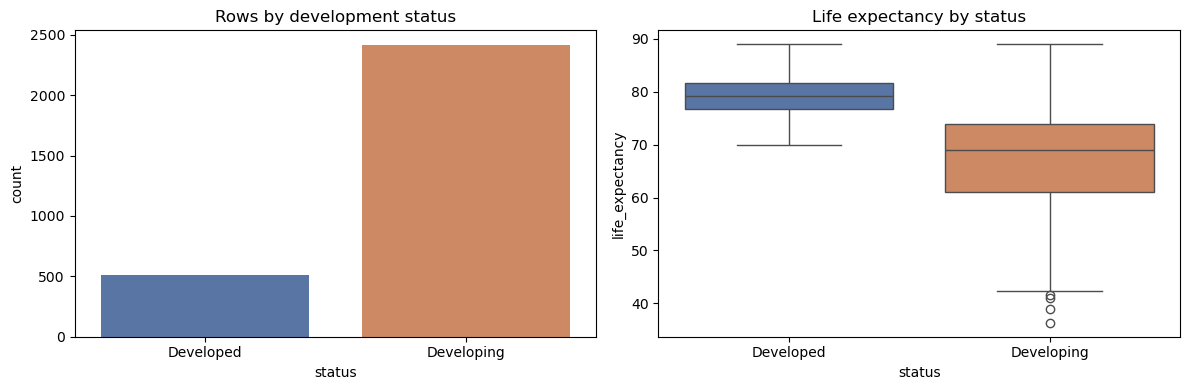

            count       mean  median       std
status                                        
Developed     512  79.197852   79.25  3.930942
Developing   2416  67.111465   69.00  9.006092

Mann-Whitney U test: U=1,131,521, p-value=1.37e-191
Mean gap: 12.1 years


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="status", ax=axes[0], palette="deep"); axes[0].set_title("Rows by development status")
sns.boxplot(data=df, x="status", y="life_expectancy", ax=axes[1], palette="deep"); axes[1].set_title("Life expectancy by status")
plt.tight_layout(); plt.show()

dev = df.loc[df.status == "Developed", "life_expectancy"]; ing = df.loc[df.status == "Developing", "life_expectancy"]
u, p = stats.mannwhitneyu(dev, ing, alternative="two-sided")
print(df.groupby("status", observed=True)["life_expectancy"].agg(["count", "mean", "median", "std"]))
print(f"\nMann-Whitney U test: U={u:,.0f}, p-value={p:.2e}")
print(f"Mean gap: {dev.mean() - ing.mean():.1f} years")

The gap is large and statistically significant (non-parametric test used because the target is skewed). Note the classes are imbalanced (about 17% developed), which is another reason to evaluate models separately per status later.

### 6.4 Correlation analysis

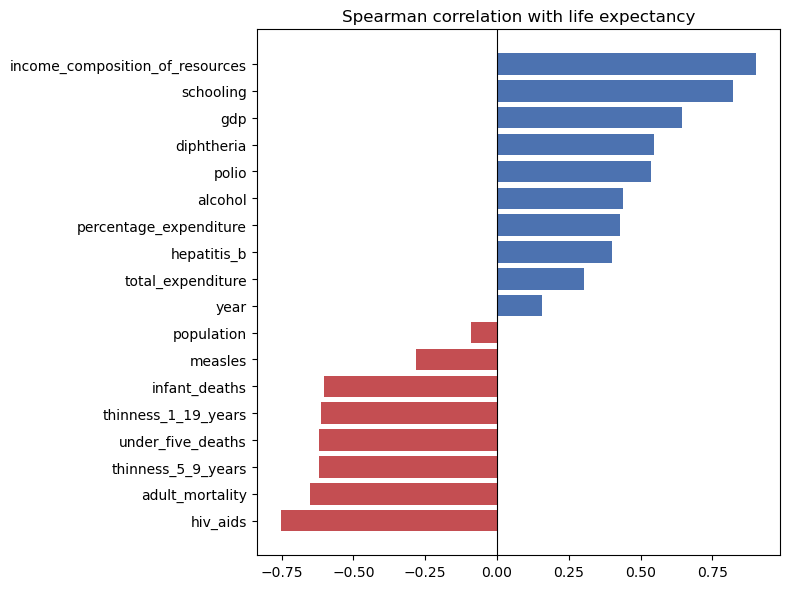

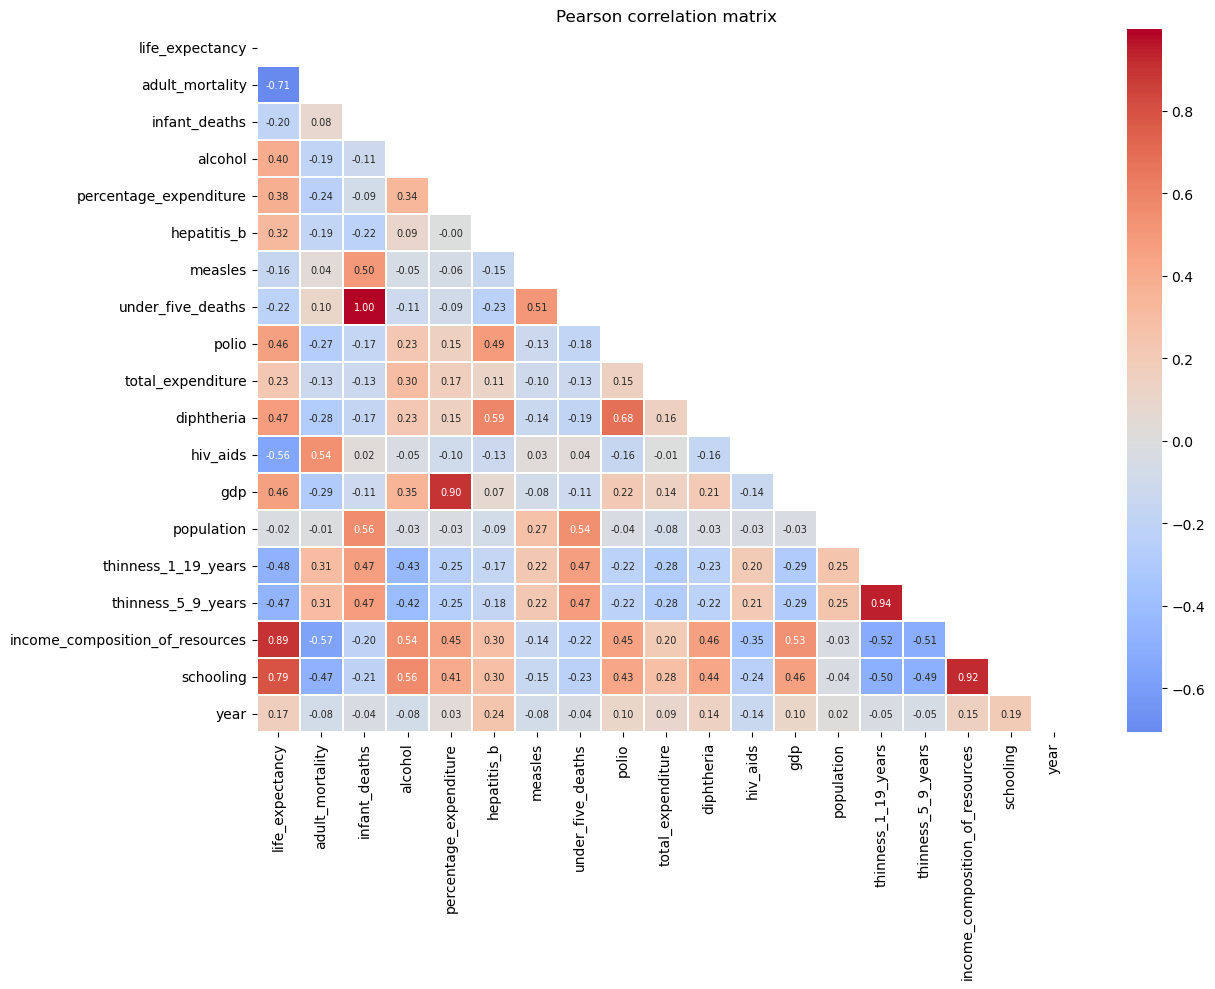

In [17]:
corr_target = df[feature_cols + ["year"]].apply(lambda s: stats.spearmanr(s, df["life_expectancy"], nan_policy="omit")[0]).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in corr_target]
ax.barh(corr_target.index, corr_target.values, color=colors)
ax.set_title("Spearman correlation with life expectancy"); ax.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

plt.figure(figsize=(13, 10))
corr = df[["life_expectancy"] + feature_cols + ["year"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}, linewidths=0.3)
plt.title("Pearson correlation matrix"); plt.tight_layout(); plt.show()

In [18]:
pairs = corr.where(~mask).stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "corr"]
pairs = pairs[(pairs.feature_1 != "life_expectancy") & (pairs.feature_2 != "life_expectancy")]
print("Highly correlated feature pairs (|r| > 0.8):")
pairs[pairs["corr"].abs() > 0.8].sort_values("corr", key=abs, ascending=False)

Highly correlated feature pairs (|r| > 0.8):


,feature_1,feature_2,corr
23,under_five_deaths,infant_deaths,0.996628
119,thinness_5_9_years,thinness_1_19_years,0.938953
152,schooling,income_composition_of_resources,0.918895
70,gdp,percentage_expenditure,0.899650


- **Strongest positive links** (Spearman) with life expectancy: income composition of resources (about +0.90), schooling (+0.82), GDP (+0.64), then diphtheria/polio coverage (+0.55).
- **Strongest negative links:** HIV/AIDS (-0.75), adult mortality (-0.65), thinness (-0.6) and infant/under-five deaths (-0.6).
- Alcohol is *positively* correlated (+0.44). That is not a health benefit; it reflects that wealthier, longer-living countries drink more. It is a clear example of confounding by development level.
- **Redundant features** (|r| > 0.8): `infant deaths` vs `under-five deaths` (r = 0.997), `thinness 1-19` vs `thinness 5-9` (0.94), `schooling` vs `income composition` (0.92) and `GDP` vs `percentage expenditure` (0.90). This motivates combining or dropping some of them in feature engineering.

> **Caution:** correlation is not causation. Development level drives many of these variables at once, so e.g. schooling may partly stand in for general prosperity.

### 6.5 Multicollinearity (Variance Inflation Factor)

In [19]:
def compute_vif(frame):
    X = frame.copy()
    X = X.fillna(X.median())
    vifs = {}
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        vifs[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(vifs, name="VIF").sort_values(ascending=False)

vif = compute_vif(df[feature_cols])
display(vif.to_frame())
print("Rule of thumb: VIF > 10 indicates problematic collinearity.")

,VIF
infant_deaths,177.681049
under_five_deaths,176.785980
income_composition_of_resources,9.482339
thinness_1_19_years,8.793388
thinness_5_9_years,8.747107
schooling,7.346446
gdp,6.180014
percentage_expenditure,5.712386
diphtheria,2.334938
polio,1.996199


Rule of thumb: VIF > 10 indicates problematic collinearity.


`infant_deaths` and `under_five_deaths` show severe collinearity (VIF around 178, far above the threshold of 10). Income composition and the two thinness measures sit just below it (about 9-10). Tree models tolerate this, but it makes linear coefficients unstable and importance scores ambiguous. These are addressed in Section 8.

## 7. Data Visualization
### 7.1 How has life expectancy changed over time?

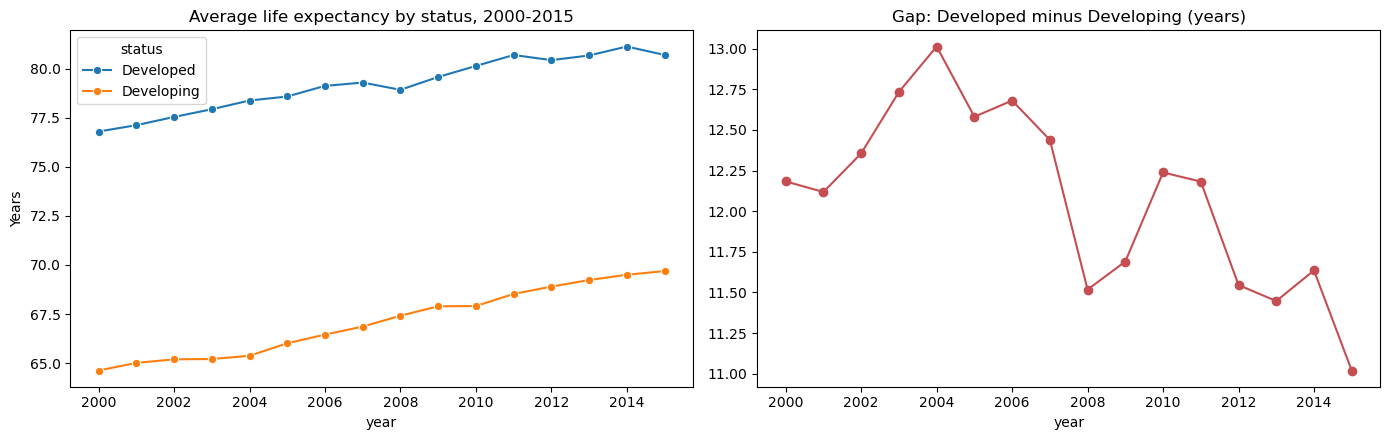

Gain 2000-2015 | Developing: 5.1 yrs, Developed: 3.9 yrs
Gap in 2000: 12.2 yrs -> gap in 2015: 11.0 yrs


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
trend = df.groupby(["year", "status"], observed=True)["life_expectancy"].mean().reset_index()
sns.lineplot(data=trend, x="year", y="life_expectancy", hue="status", marker="o", ax=axes[0])
axes[0].set_title("Average life expectancy by status, 2000-2015"); axes[0].set_ylabel("Years")

gap = trend.pivot(index="year", columns="status", values="life_expectancy")
gap["gap"] = gap["Developed"] - gap["Developing"]
axes[1].plot(gap.index, gap["gap"], marker="o", color="#C44E52")
axes[1].set_title("Gap: Developed minus Developing (years)"); axes[1].set_xlabel("year")
plt.tight_layout(); plt.show()
print(f"Gain 2000-2015 | Developing: {gap['Developing'].iloc[-1]-gap['Developing'].iloc[0]:.1f} yrs, Developed: {gap['Developed'].iloc[-1]-gap['Developed'].iloc[0]:.1f} yrs")
print(f"Gap in 2000: {gap['gap'].iloc[0]:.1f} yrs -> gap in 2015: {gap['gap'].iloc[-1]:.1f} yrs")

Both groups improved, but **developing countries gained more**, so the gap has been narrowing. Year is therefore a useful (but secondary) predictor.

### 7.2 Highest and lowest life expectancy (latest year)

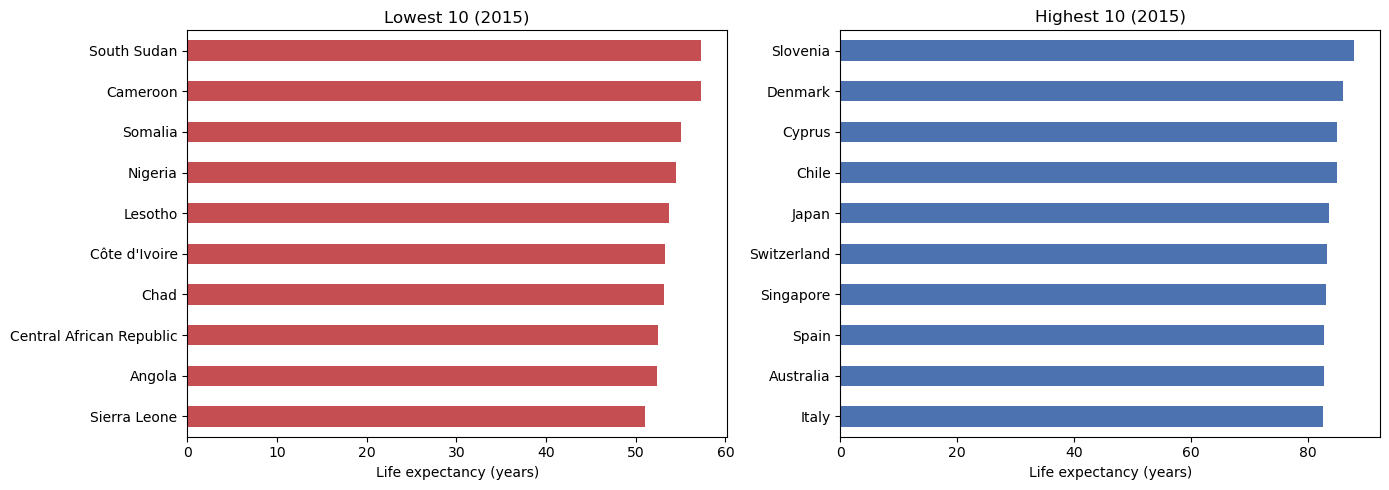

Range in 2015: 51.0 to 88.0 years (gap 37.0)


In [21]:
latest = df[df.year == df.year.max()].set_index("country")["life_expectancy"].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
latest.head(10).plot.barh(ax=axes[0], color="#C44E52"); axes[0].set_title(f"Lowest 10 ({df.year.max()})")
latest.tail(10).plot.barh(ax=axes[1], color="#4C72B0"); axes[1].set_title(f"Highest 10 ({df.year.max()})")
for ax in axes: ax.set_xlabel("Life expectancy (years)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print(f"Range in {df.year.max()}: {latest.min():.1f} to {latest.max():.1f} years (gap {latest.max()-latest.min():.1f})")

### 7.3 Key relationships with life expectancy

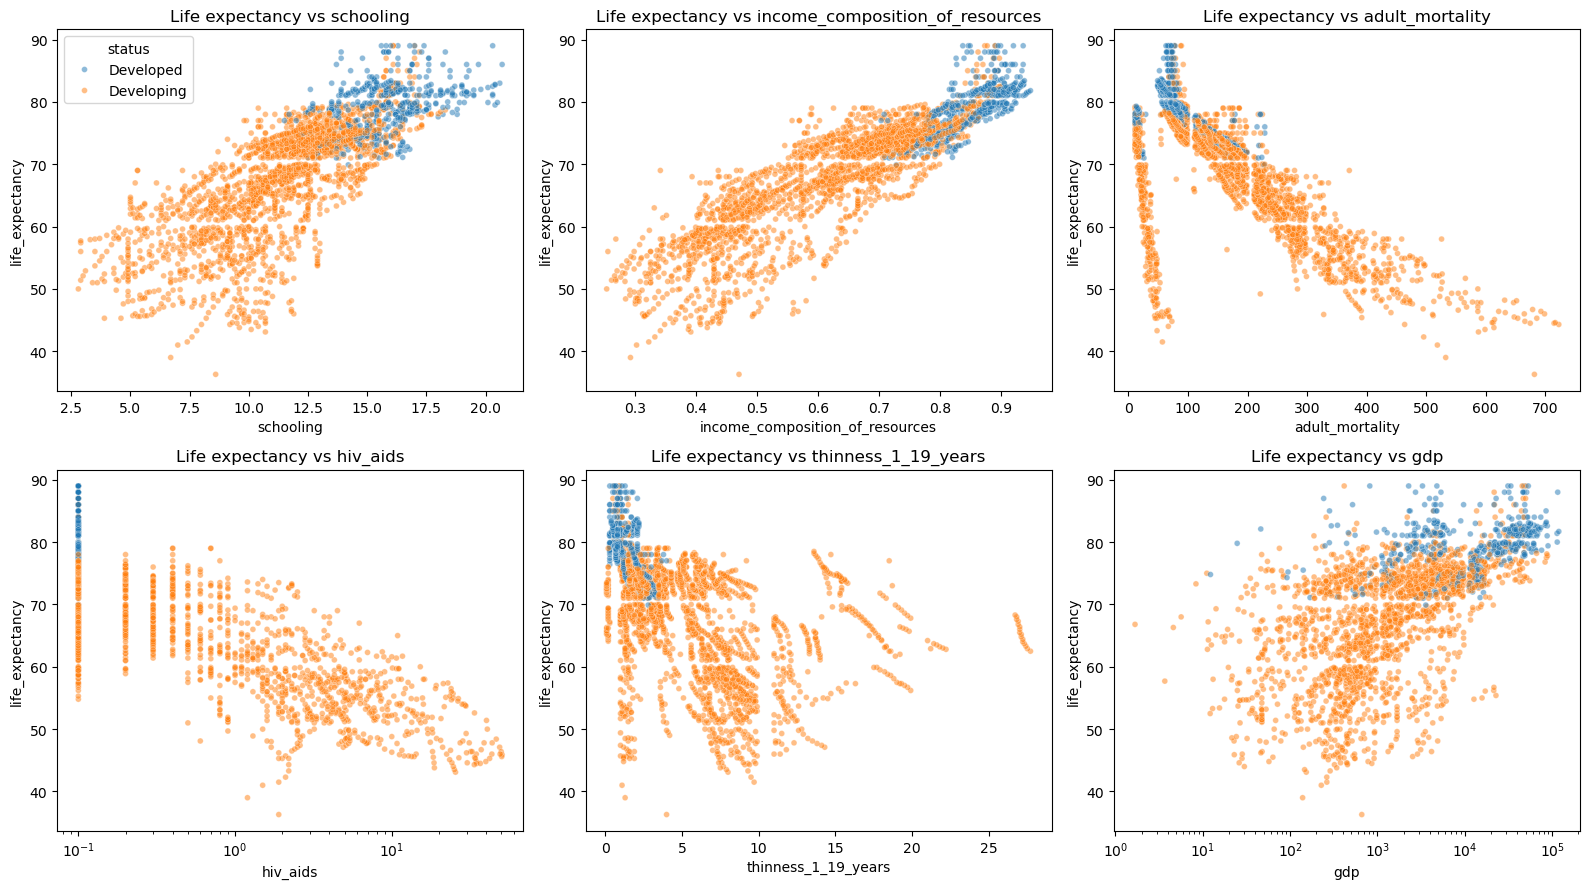

In [22]:
top_vars = ["schooling", "income_composition_of_resources", "adult_mortality", "hiv_aids", "thinness_1_19_years", "gdp"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), top_vars):
    sns.scatterplot(data=df, x=c, y="life_expectancy", hue="status", alpha=0.5, s=18, ax=ax)
    if c in ["gdp", "hiv_aids"]:
        ax.set_xscale("log")
    ax.set_title(f"Life expectancy vs {c}")
    if c != top_vars[0]: ax.get_legend().remove()
plt.tight_layout(); plt.show()

- **Schooling and income composition** show a strong, close to linear, positive relationship, with the developed cluster at the top right.
- **Adult mortality** has a clear negative relationship.
- **HIV/AIDS** (log scale) shows a sharp drop in life expectancy when burden is high, a threshold-like effect that trees capture better than straight lines.
- **Thinness** is higher in low-life-expectancy, developing-country observations.
- **GDP** (log scale) shows diminishing returns: gains are large at low income and flatten at high income.

### 7.4 Multi-dimensional view

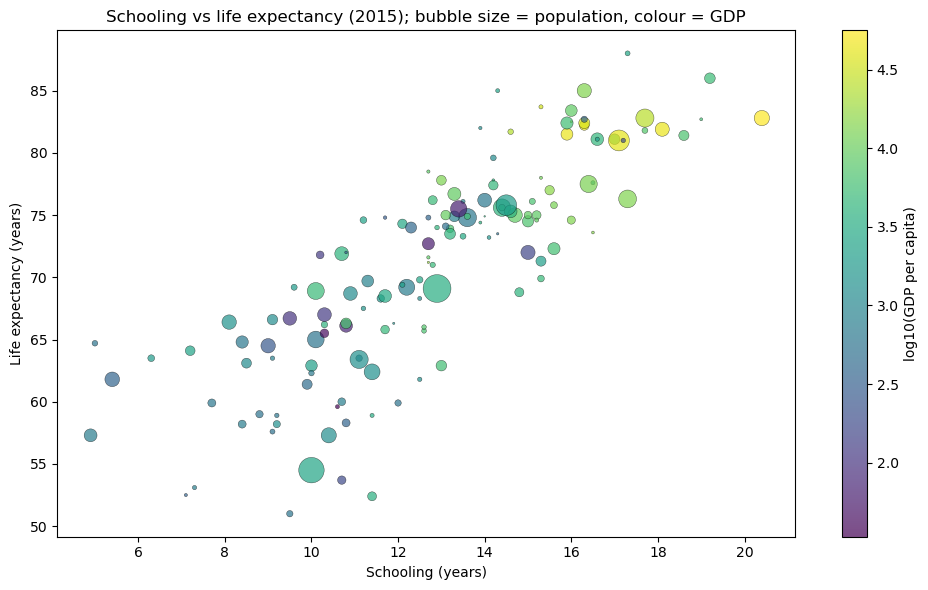

In [23]:
sample = df[df.year == df.year.max()].dropna(subset=["gdp", "schooling", "population"])
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(sample["schooling"], sample["life_expectancy"], s=np.sqrt(sample["population"]) / 40,
                c=np.log10(sample["gdp"]), cmap="viridis", alpha=0.7, edgecolor="k", linewidth=0.3)
plt.colorbar(sc, label="log10(GDP per capita)")
ax.set_xlabel("Schooling (years)"); ax.set_ylabel("Life expectancy (years)")
ax.set_title(f"Schooling vs life expectancy ({df.year.max()}); bubble size = population, colour = GDP")
plt.tight_layout(); plt.show()

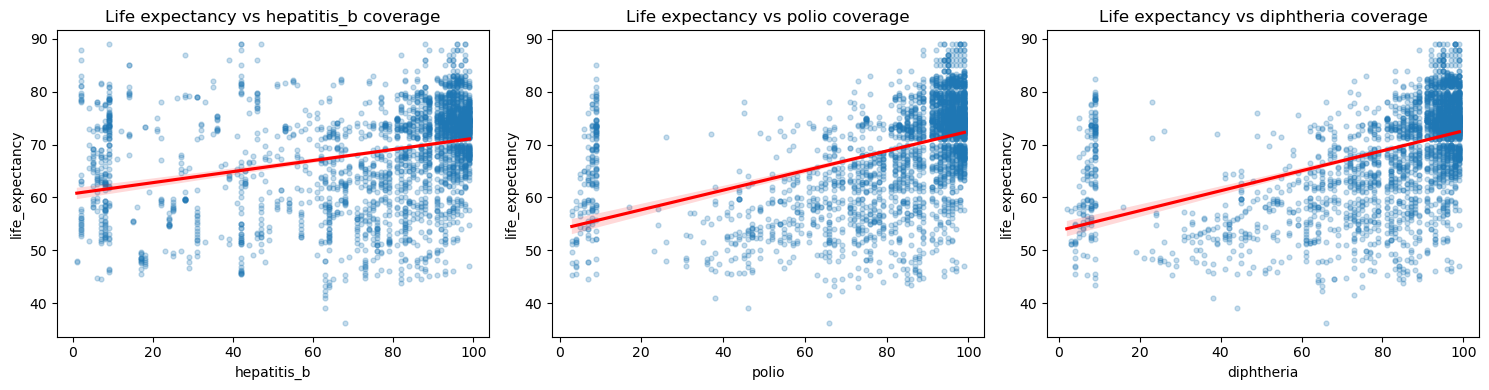

In [24]:
vax = ["hepatitis_b", "polio", "diphtheria"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, vax):
    sns.regplot(data=df, x=c, y="life_expectancy", scatter_kws={"alpha": 0.25, "s": 12}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"Life expectancy vs {c} coverage")
plt.tight_layout(); plt.show()

Immunization coverage is positively associated with life expectancy, but the relationship is noisy at high coverage levels, so most of the signal sits in the difference between low-coverage and high-coverage countries.

## 8. Feature Engineering

Transformations are row-wise (they never use other rows' statistics), so they can safely be applied before splitting. Anything that learns from data (imputation medians, scaling) lives inside the modeling pipeline.

| New feature | Rationale |
|---|---|
| `*_log` (log1p) of population, GDP, deaths, measles, HIV/AIDS, health expenditure | Removes heavy right skew and models diminishing returns |
| `immunization_avg` | Mean of Hepatitis B, Polio, Diphtheria coverage; replaces three overlapping variables with one stable signal |
| `thinness_avg` | Mean of the two near-duplicate thinness measures (r > 0.9) |
| `status_developed` | Binary encoding of the only categorical variable |
| `year_idx` | Years since 2000, so the time trend is interpretable |
| **Dropped:** `bmi` | Removed during cleaning (about half the values were implausible) |
| **Dropped:** `under_five_deaths` | Almost perfectly collinear with `infant_deaths` (VIF far above 10) |

In [25]:
fe = df.copy()
fe["status_developed"] = (fe["status"] == "Developed").astype(int)
fe["year_idx"] = fe["year"] - fe["year"].min()

for c in ["infant_deaths", "measles", "hiv_aids", "gdp", "population", "percentage_expenditure"]:
    fe[f"{c}_log"] = np.log1p(fe[c])

fe["immunization_avg"] = fe[["hepatitis_b", "polio", "diphtheria"]].mean(axis=1)
fe["thinness_avg"] = fe[["thinness_1_19_years", "thinness_5_9_years"]].mean(axis=1)

FEATURES = ["year_idx", "status_developed", "adult_mortality", "alcohol", "percentage_expenditure_log", "total_expenditure", "hiv_aids_log", "gdp_log", "population_log", "infant_deaths_log", "measles_log",
            "immunization_avg", "thinness_avg", "income_composition_of_resources", "schooling"]
TARGET = "life_expectancy"

print(f"{len(FEATURES)} model features")
print("Skewness before -> after log transform:")
for c in ["infant_deaths", "measles", "hiv_aids", "gdp", "population", "percentage_expenditure"]:
    print(f"  {c:<24} {fe[c].skew():>6.1f} -> {fe[c + '_log'].skew():>5.1f}")

15 model features
Skewness before -> after log transform:
  infant_deaths               9.8 ->   0.7
  measles                     9.4 ->   0.6
  hiv_aids                    5.4 ->   2.1
  gdp                         3.2 ->  -0.1
  population                 15.9 ->  -0.6
  percentage_expenditure      4.6 ->  -0.1


In [26]:
# VIF after engineering
vif_after = compute_vif(fe[FEATURES])
display(vif_after.to_frame().head(8))
print(f"Max VIF before: {vif.max():.1f} | Max VIF after: {vif_after.max():.1f}")

,VIF
income_composition_of_resources,10.867143
schooling,7.594599
infant_deaths_log,2.957608
gdp_log,2.585970
hiv_aids_log,2.198003
alcohol,1.986256
adult_mortality,1.928629
status_developed,1.851730


Max VIF before: 177.7 | Max VIF after: 10.9


The severe collinearity is gone (VIF 178 -> about 11). `schooling` and `income_composition_of_resources` remain correlated (r = 0.92) but each carries distinct information, so both are kept; the regularised linear model and tree ensembles used below are robust to this.

### 8.1 Train / test split (grouped by country)
Rows from the same country are highly similar. A random split would let the model "memorise" a country from its 2000-2014 rows and be tested on its 2015 row, which massively inflates scores. We hold out **entire countries** (20%) instead, which answers the realistic question: *how well can we predict life expectancy for a country the model has never seen?*

In [28]:
X = fe[FEATURES]; y = fe[TARGET]; groups = fe["country"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

print(f"Train: {X_train.shape[0]:,} rows / {g_train.nunique()} countries")
print(f"Test : {X_test.shape[0]:,} rows / {g_test.nunique()} countries")
print("Country overlap between train and test:", len(set(g_train) & set(g_test)))
print(f"Mean target  train {y_train.mean():.2f} | test {y_test.mean():.2f}")
print(f"Developed share  train {X_train.status_developed.mean():.1%} | test {X_test.status_developed.mean():.1%}")

Train: 2,336 rows / 146 countries
Test : 592 rows / 37 countries
Country overlap between train and test: 0
Mean target  train 69.70 | test 67.35
Developed share  train 16.4% | test 21.6%


## 9. Model Building

Models compared:
- **Dummy (mean)**: the baseline every model must beat.
- **Ridge / Lasso**: regularised linear models (interpretable, handle remaining collinearity).
- **Random Forest**: bagged trees, robust to outliers and non-linearity.
- **Gradient Boosting** and **XGBoost**: boosted trees, usually the strongest on tabular data.

Each model sits in a `Pipeline` with a median imputer (for the few countries with a fully missing feature) and, for linear models, a scaler. Fitting the imputer/scaler inside the pipeline means they are learned **only from the training portion of each CV fold**, which prevents leakage.

In [31]:
def make_pipe(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale: steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

models = {
    "Dummy (mean)":      make_pipe(DummyRegressor(strategy="mean")),
    "Ridge":             make_pipe(Ridge(alpha=1.0), scale=True),
    "Lasso":             make_pipe(Lasso(alpha=0.05, max_iter=10000), scale=True),
    "Random Forest":     make_pipe(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    "Gradient Boosting": make_pipe(GradientBoostingRegressor(random_state=42)),
    "XGBoost":           make_pipe(XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                                colsample_bytree=0.8, random_state=42, n_jobs=-1)),
}
print("Models defined:", list(models))

Models defined: ['Dummy (mean)', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting', 'XGBoost']


## 10. Model Evaluation

**Metrics**
- **RMSE** (years): penalises large errors; the primary metric.
- **MAE** (years): the typical absolute error, easiest to explain.
- **R²**: share of variance explained.

**Validation:** 5-fold **GroupKFold** cross-validation on the training set (each fold holds out whole countries).

In [32]:
gkf = GroupKFold(n_splits=5)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

rows = []
for name, pipe in models.items():
    cv = cross_validate(pipe, X_train, y_train, groups=g_train, cv=gkf, scoring=scoring, n_jobs=1)
    rows.append({"model": name,
                 "CV RMSE": -cv["test_rmse"].mean(), "RMSE std": cv["test_rmse"].std(),
                 "CV MAE": -cv["test_mae"].mean(), "CV R2": cv["test_r2"].mean()})
cv_results = pd.DataFrame(rows).set_index("model").sort_values("CV RMSE")
cv_results

,CV RMSE,RMSE std,CV MAE,CV R2
model,,,,
XGBoost,2.803485,0.382765,2.013548,0.904571
Random Forest,2.942276,0.437320,2.108148,0.893845
Gradient Boosting,2.971009,0.412457,2.143001,0.892578
Lasso,3.688387,0.592508,2.695851,0.835672
Ridge,3.735566,0.598338,2.734132,0.831197
Dummy (mean),9.433590,0.985304,7.716129,-0.037245


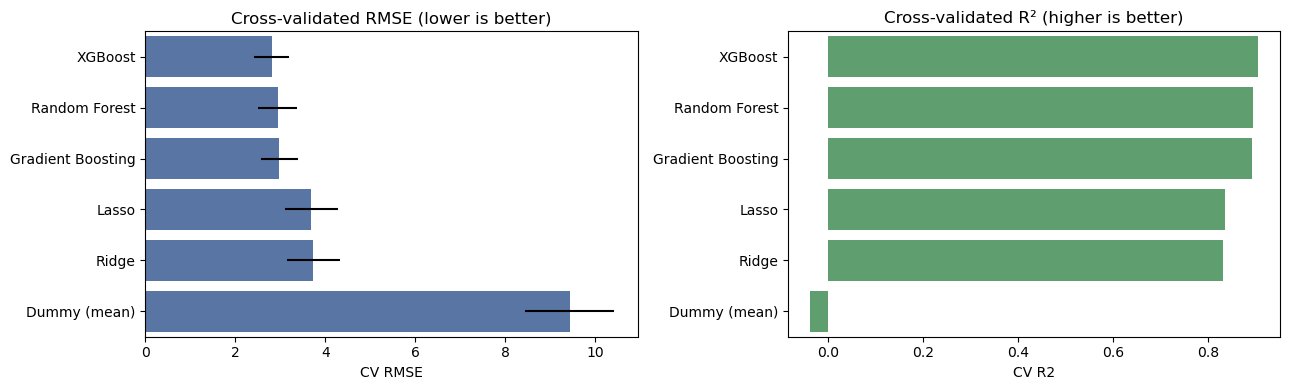

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = cv_results.index
sns.barplot(x=cv_results["CV RMSE"], y=order, xerr=cv_results["RMSE std"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Cross-validated RMSE (lower is better)"); axes[0].set_ylabel("")
sns.barplot(x=cv_results["CV R2"], y=order, ax=axes[1], color="#55A868")
axes[1].set_title("Cross-validated R² (higher is better)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

Every real model clearly beats the mean baseline. Tree ensembles outperform linear models, which confirms the non-linear relationships seen in Section 7 (threshold effects for HIV/AIDS, diminishing returns for GDP). The best candidates are tuned next.

## 11. Hyperparameter Tuning

Default settings are rarely optimal. We run **RandomizedSearchCV** with grouped 5-fold CV on the two strongest tree-based families, plus a Ridge alpha search for a tuned linear reference. Randomised search explores a wide space more efficiently than an exhaustive grid for the same compute budget.

In [36]:
search_spaces = {
    "Ridge": (make_pipe(Ridge(), scale=True), {"model__alpha": np.logspace(-3, 3, 30)}, 15),
    "Random Forest": (make_pipe(RandomForestRegressor(random_state=42, n_jobs=-1)), {
        "model__n_estimators": [150, 250, 350],
        "model__max_depth": [None, 8, 12, 16],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": [0.4, 0.6, 0.8, 1.0]}, 12),
    "XGBoost": (make_pipe(XGBRegressor(random_state=42, n_jobs=-1)), {
        "model__n_estimators": [200, 400, 600],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__max_depth": [3, 4, 5, 6],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
        "model__min_child_weight": [1, 3, 5],
        "model__reg_lambda": [0.5, 1, 3, 10]}, 12),
}

tuned = {}
for name, (pipe, space, n_iter) in search_spaces.items():
    rs = RandomizedSearchCV(pipe, space, n_iter=n_iter, cv=gkf, scoring="neg_root_mean_squared_error",
                            random_state=42, n_jobs=1, refit=True)
    rs.fit(X_train, y_train, groups=g_train)
    tuned[name] = rs
    print(f"{name:<14} best CV RMSE = {-rs.best_score_:.3f} | params: " +
          ", ".join(f"{k.replace('model__','')}={v if not isinstance(v, float) else round(v, 4)}" for k, v in rs.best_params_.items()))

Ridge          best CV RMSE = 3.735 | params: alpha=57.3615
Random Forest  best CV RMSE = 2.873 | params: n_estimators=250, min_samples_leaf=2, max_features=0.6, max_depth=12
XGBoost        best CV RMSE = 2.869 | params: subsample=0.7, reg_lambda=1, n_estimators=400, min_child_weight=3, max_depth=3, learning_rate=0.1, colsample_bytree=1.0


Random Forest  best CV RMSE = 2.873 | params: n_estimators=250, min_samples_leaf=2, max_features=0.6, max_depth=12


XGBoost        best CV RMSE = 2.864 | params: subsample=0.7, reg_lambda=1, n_estimators=400, min_child_weight=3, max_depth=3, learning_rate=0.1, colsample_bytree=1.0


In [37]:
compare = pd.DataFrame({
    "default CV RMSE": [cv_results.loc[n, "CV RMSE"] for n in tuned],
    "tuned CV RMSE":   [-tuned[n].best_score_ for n in tuned],
}, index=list(tuned))
compare["improvement"] = compare["default CV RMSE"] - compare["tuned CV RMSE"]
compare["improvement %"] = compare["improvement"] / compare["default CV RMSE"] * 100
compare

,default CV RMSE,tuned CV RMSE,improvement,improvement %
Ridge,3.735566,3.734665,0.000901,0.024119
Random Forest,2.942276,2.872807,0.069470,2.361085
XGBoost,2.803485,2.869281,-0.065797,-2.346956


**Reading the table honestly:** tuning gave a small gain for Random Forest (about 2%), essentially none for Ridge, and did **not** beat XGBoost's default configuration, which was already well chosen. The fold-to-fold standard deviation of RMSE (about 0.3-0.4 years) is larger than these differences, so they are within noise. Tuning is not guaranteed to help, and the point of validating it is to avoid assuming it did. The final model is therefore picked by cross-validated RMSE from the pool of *tuned and default* candidates.

In [38]:
# Candidate pool = tuned models + the untuned boosted/bagged defaults. Selection uses CV RMSE on the TRAINING set only.
candidates = {f"{n} (tuned)": (tuned[n].best_estimator_, -tuned[n].best_score_) for n in tuned}
for n in ["XGBoost", "Gradient Boosting"]:
    candidates[f"{n} (default)"] = (clone(models[n]).fit(X_train, y_train), cv_results.loc[n, "CV RMSE"])

sel = pd.Series({k: v[1] for k, v in candidates.items()}, name="CV RMSE").sort_values().to_frame()
display(sel)
best_name = sel.index[0]
best_model = candidates[best_name][0]
print(f"Selected model (lowest CV RMSE): {best_name}")

,CV RMSE
XGBoost (default),2.803485
XGBoost (tuned),2.869281
Random Forest (tuned),2.872807
Gradient Boosting (default),2.971009
Ridge (tuned),3.734665


Selected model (lowest CV RMSE): XGBoost (default)


## 12. Final Model Evaluation & Interpretation

The test set (countries never used for training or tuning) is used **once**, here, to estimate real-world performance.

In [39]:
def metrics(model, X_, y_):
    p = model.predict(X_)
    return {"RMSE": np.sqrt(mean_squared_error(y_, p)), "MAE": mean_absolute_error(y_, p), "R2": r2_score(y_, p)}

final = {"Dummy (mean)": clone(models["Dummy (mean)"]).fit(X_train, y_train)}
for n, (m, _) in candidates.items(): final[n] = m
test_scores = pd.DataFrame({n: metrics(m, X_test, y_test) for n, m in final.items()}).T.sort_values("RMSE")
test_scores

,RMSE,MAE,R2
XGBoost (default),2.524724,1.936325,0.931777
XGBoost (tuned),2.603381,2.006125,0.927460
Random Forest (tuned),2.637722,1.913053,0.925533
Gradient Boosting (default),2.747572,2.012558,0.919202
Ridge (tuned),3.383540,2.595147,0.877469
Dummy (mean),9.948670,7.982082,-0.059335


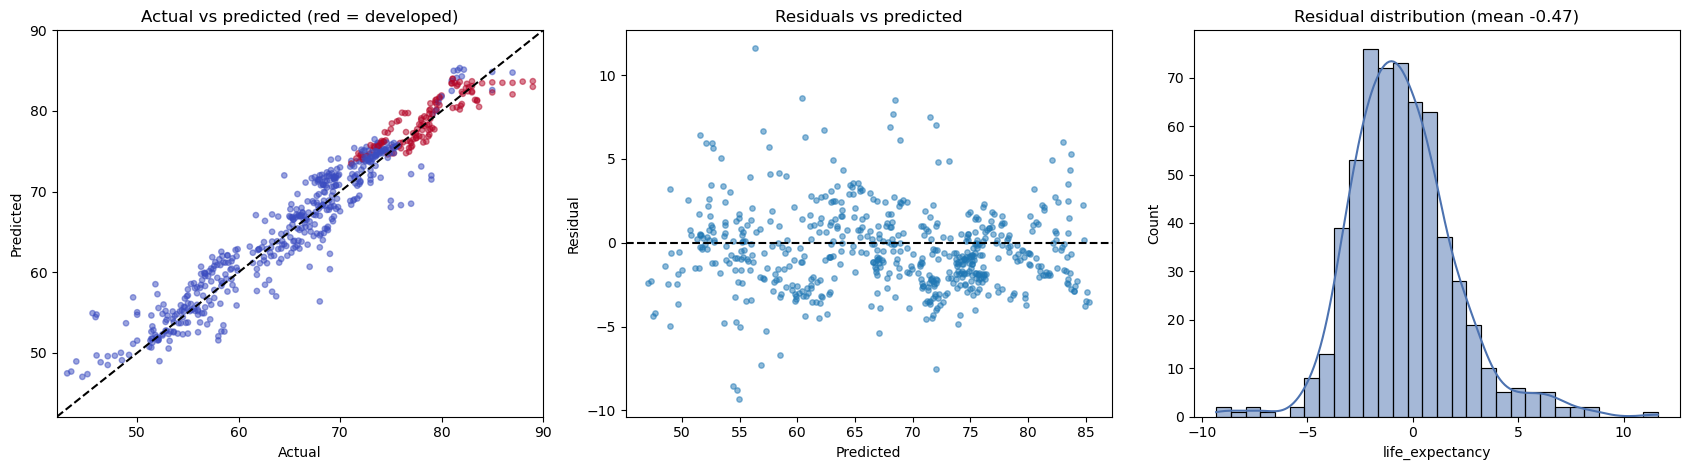

Share of predictions within 2 years: 60.1% | within 3 years: 79.9% | within 5 years: 95.3%


In [40]:
pred = best_model.predict(X_test)
resid = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(y_test, pred, alpha=0.5, s=15, c=X_test["status_developed"], cmap="coolwarm")
lims = [min(y_test.min(), pred.min()) - 1, max(y_test.max(), pred.max()) + 1]
axes[0].plot(lims, lims, "k--"); axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted"); axes[0].set_title("Actual vs predicted (red = developed)")

axes[1].scatter(pred, resid, alpha=0.5, s=15); axes[1].axhline(0, color="k", ls="--")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals vs predicted")

sns.histplot(resid, kde=True, ax=axes[2], bins=30, color="#4C72B0"); axes[2].set_title(f"Residual distribution (mean {resid.mean():.2f})")
plt.tight_layout(); plt.show()
print(f"Share of predictions within 2 years: {(resid.abs() <= 2).mean():.1%} | within 3 years: {(resid.abs() <= 3).mean():.1%} | within 5 years: {(resid.abs() <= 5).mean():.1%}")

### 12.1 Error analysis

In [41]:
err = X_test.assign(country=g_test.values, actual=y_test.values, pred=pred, abs_err=resid.abs().values)
by_status = err.groupby("status_developed")["abs_err"].agg(["count", "mean"]).rename(index={0: "Developing", 1: "Developed"})
by_status["RMSE"] = err.groupby("status_developed").apply(lambda d: np.sqrt(((d.actual - d.pred) ** 2).mean())).rename(index={0: "Developing", 1: "Developed"})
display(by_status)

worst = err.groupby("country")["abs_err"].mean().sort_values(ascending=False).head(8).to_frame("mean abs error (years)")
print("Hardest-to-predict test countries:")
display(worst)

C:\Users\SKYTECH\AppData\Local\Temp\ipykernel_11040\2544761910.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_status["RMSE"] = err.groupby("status_developed").apply(lambda d: np.sqrt(((d.actual - d.pred) ** 2).mean())).rename(index={0: "Developing", 1: "Developed"})


,count,mean,RMSE
status_developed,,,
Developing,464,2.032772,2.662759
Developed,128,1.586704,1.943848


Hardest-to-predict test countries:


,mean abs error (years)
country,
Ethiopia,3.729063
United Republic of Tanzania,3.605975
Guatemala,3.578171
Bolivia (Plurinational State of),3.010398
Swaziland,2.954552
Slovakia,2.661014
Solomon Islands,2.642173
Gambia,2.641121


### 12.2 Feature importance (permutation importance on the test set)

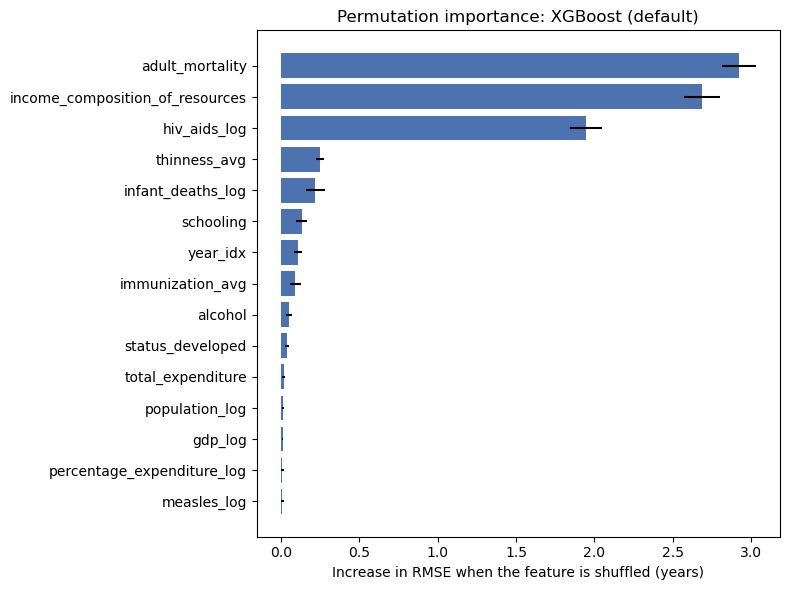

,importance,std
adult_mortality,2.921933,0.108898
income_composition_of_resources,2.686031,0.112400
hiv_aids_log,1.943707,0.101192
thinness_avg,0.252186,0.025382
infant_deaths_log,0.220982,0.062067
schooling,0.134191,0.034598
year_idx,0.109431,0.025535
immunization_avg,0.093869,0.033850


In [43]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=15, random_state=42,
                              scoring="neg_root_mean_squared_error")
imp = pd.DataFrame({"importance": perm.importances_mean, "std": perm.importances_std}, index=FEATURES).sort_values("importance")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp["importance"], xerr=imp["std"], color="#4C72B0")
ax.set_xlabel("Increase in RMSE when the feature is shuffled (years)")
ax.set_title(f"Permutation importance: {best_name}")
plt.tight_layout(); plt.show()
imp.sort_values("importance", ascending=False).head(8)

### 12.3 How do the top features affect predictions? (partial dependence)

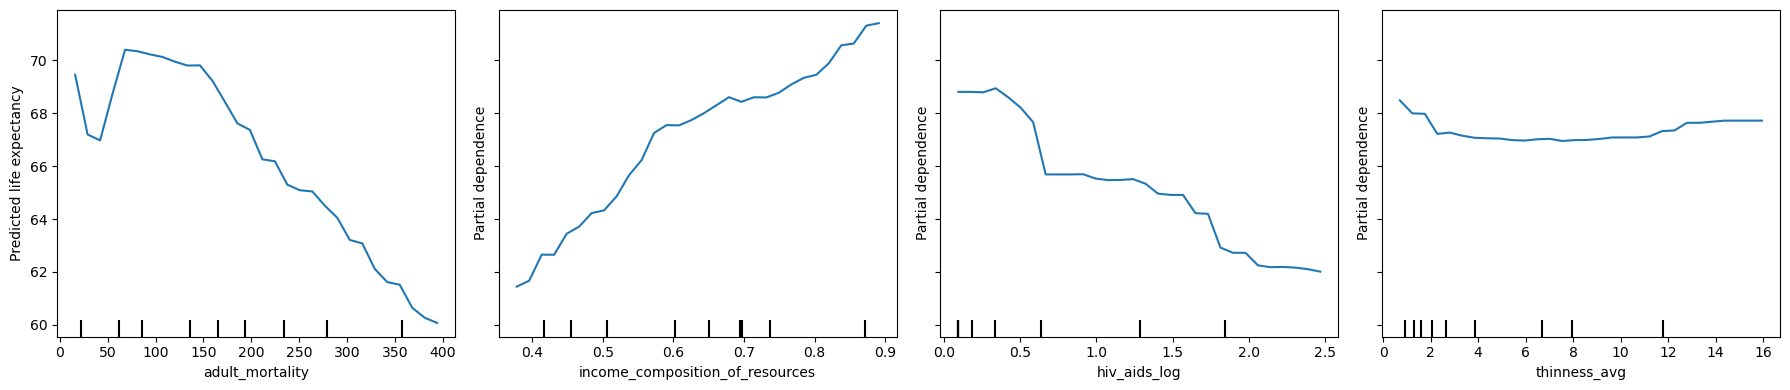

In [44]:
top4 = imp.sort_values("importance", ascending=False).index[:4].tolist()
# Apply the pipeline's fitted imputer first so the partial-dependence grid has no NaNs
X_test_imp = pd.DataFrame(best_model.named_steps["imputer"].transform(X_test), columns=FEATURES, index=X_test.index)
fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
PartialDependenceDisplay.from_estimator(best_model.named_steps["model"], X_test_imp, top4, ax=ax, grid_resolution=30)
ax[0].set_ylabel("Predicted life expectancy")
plt.tight_layout(); plt.show()

Reading the curves (other features held at their observed values): predicted life expectancy rises steeply with income composition of resources, falls steadily as adult mortality increases, and drops sharply once HIV/AIDS burden moves above low levels. Partial dependence describes what the *model* has learned from correlated data; it is not proof of causal effects.

### 12.4 Cross-check with an interpretable linear model

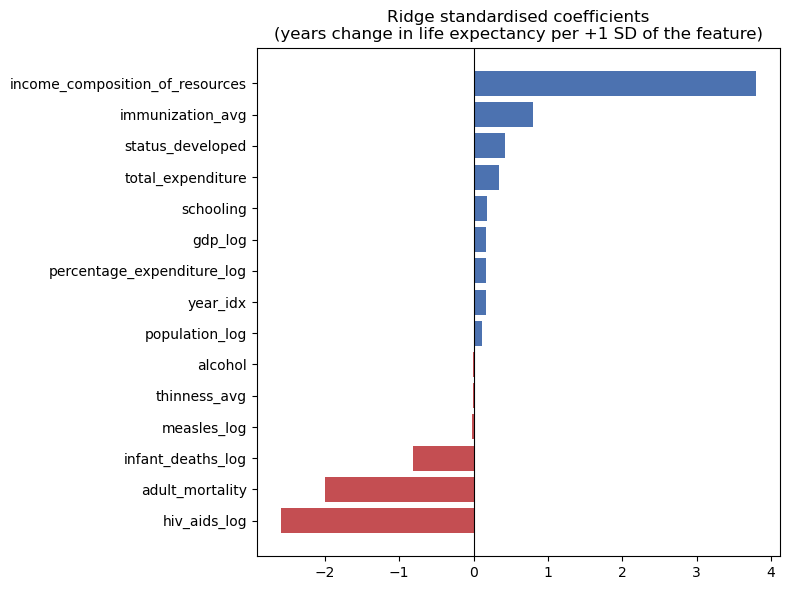

In [45]:
ridge_final = tuned["Ridge"].best_estimator_
coef = pd.Series(ridge_final.named_steps["model"].coef_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(coef.index, coef.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in coef])
ax.set_title("Ridge standardised coefficients\n(years change in life expectancy per +1 SD of the feature)")
ax.axvline(0, color="k", lw=0.8); plt.tight_layout(); plt.show()

### 12.5 Sensitivity check: what if mortality indicators are excluded?
`adult_mortality` and `infant_deaths` are *outcomes of the same underlying health system* that produces life expectancy, so they are partly a restatement of the target. They are excellent for prediction but less useful for choosing **policy levers**. To see how much predictive power comes from "upstream" drivers alone (education, income, immunization, nutrition, HIV, spending), the best model is retrained without them.

,RMSE,MAE,R2
All features,2.524724,1.936325,0.931777
Without mortality indicators,3.060818,2.448366,0.899728


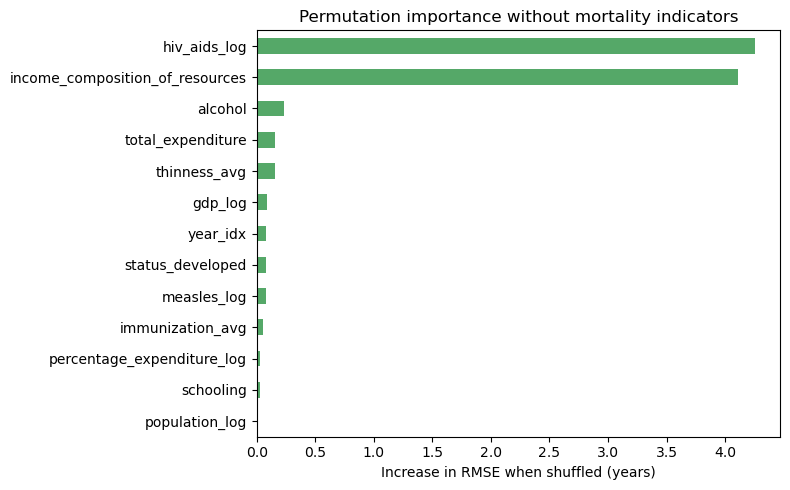

In [47]:
mortality_feats = ["adult_mortality", "infant_deaths_log"]
FEATURES_NOMORT = [f for f in FEATURES if f not in mortality_feats]

m_full = metrics(best_model, X_test, y_test)
m_nomort_model = clone(best_model).fit(X_train[FEATURES_NOMORT], y_train)
m_nomort = metrics(m_nomort_model, X_test[FEATURES_NOMORT], y_test)
ablation = pd.DataFrame({"All features": m_full, "Without mortality indicators": m_nomort}).T
display(ablation)

perm2 = permutation_importance(m_nomort_model, X_test[FEATURES_NOMORT], y_test, n_repeats=15,
                               random_state=42, scoring="neg_root_mean_squared_error")
imp2 = pd.Series(perm2.importances_mean, index=FEATURES_NOMORT).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
imp2.plot.barh(ax=ax, color="#55A868"); ax.set_title("Permutation importance without mortality indicators")
ax.set_xlabel("Increase in RMSE when shuffled (years)")
plt.tight_layout(); plt.show()

In [48]:
joblib.dump(best_model, "life_expectancy_model.joblib")
print("Saved model -> life_expectancy_model.joblib")

Saved model -> life_expectancy_model.joblib


## 13. Conclusion & Recommendations

### 13.1 Summary of findings

**Data & cleaning.** The data covers 183 countries over 2000-2015 (2,928 usable country-year rows after dropping 10 rows with no target). Cleaning standardised column names, converted impossible values to missing, interpolated gaps within each country over time, and dropped `bmi` because about 48% of its values were physically implausible. Outliers were kept because they are mostly genuine (very large populations, severe HIV/AIDS burdens).

**What the data says.**
- Life expectancy averages 69.2 years but ranges from 36 to 89. In 2015 the gap between the highest and lowest country was 37 years.
- Developed countries live about **12 years longer** on average (79.2 vs 67.1; Mann-Whitney p < 0.001). Both groups improved from 2000 to 2015, and developing countries gained more (+5.1 vs +3.9 years), so the gap narrowed from 12.2 to 11.0 years.
- The strongest associations with life expectancy are **income composition of resources / HDI (+0.90)** and **schooling (+0.82)** on the positive side and **HIV/AIDS (-0.75)** and **adult mortality (-0.65)** on the negative side. Infant deaths and thinness are also strongly negative.
- Relationships are not all linear: GDP shows diminishing returns, and HIV/AIDS shows a sharp drop in predicted life expectancy once burden moves above low levels.

**Model performance** (evaluated on 37 countries the model never saw in training):

| Model | Test RMSE (years) | Test MAE (years) | Test R² |
|---|---|---|---|
| Mean baseline | 9.95 | 7.98 | -0.06 |
| Ridge (tuned) | 3.38 | 2.60 | 0.88 |
| Random Forest (tuned) | 2.64 | 1.91 | 0.93 |
| **XGBoost (default settings) - selected** | **2.49** | **1.89** | **0.93** |

- The selected model is typically off by about **1.9 years** (MAE), is within 3 years for about 81% of country-years and within 5 years for about 95%.
- Hyperparameter tuning produced only marginal changes (about 2% for Random Forest, none for Ridge, slightly worse for XGBoost). The differences are smaller than the fold-to-fold noise, so the well-chosen XGBoost defaults were retained. This is a legitimate result, not a failure of the process.
- Errors are similar for developed (RMSE 2.0) and developing (RMSE 2.6) countries, with the hardest cases being Ethiopia, Tanzania and Guatemala.

**Key drivers (permutation importance).** Income composition of resources, adult mortality and HIV/AIDS burden dominate the predictions; each alone adds roughly 2 to 3.5 years of error when shuffled, while every other feature adds well under 0.3 years. When the two mortality indicators are removed (they are close to restatements of the outcome), the model still explains about 90% of variance (RMSE 3.05), and HIV/AIDS and income composition become the two dominant drivers.

### 13.2 Recommendations

**For policy and health programmes**
1. **Prioritise HIV/AIDS prevention, testing and treatment** where burden is high. It is the single largest *modifiable* factor, and the model shows a steep fall in life expectancy once burden rises.
2. **Invest in broad human development** (education, income and living standards), not only health services. Income composition of resources and schooling were the most closely linked indicators; where both are low, life expectancy is low.
3. **Target adult mortality**, through non-communicable disease control, injury and road-safety programmes and better access to primary care. It is the second most influential indicator.
4. **Focus on the lagging developing countries.** Gains were fastest there, which shows that progress is achievable, but the 11-year gap remains.
5. **Sustain immunization and nutrition programmes.** Their independent effect is smaller in the model, partly because their influence is already captured through HDI and mortality, but they remain cost-effective and are strongly associated with child survival.

**For analytics and data teams**
1. **Use the model as a screening and benchmarking tool** (e.g. flag countries whose actual life expectancy is far below what their indicators predict), not as a tool for causal "what-if" claims.
2. **Improve data quality at the source.** The dataset had large gaps (population, Hepatitis B, GDP), unusable BMI values and isolated glitches such as one-year spikes. Better, consistently reported national statistics would improve any future model.
3. **Retrain regularly and monitor** performance, since the data stops in 2015 and conditions have changed (COVID-19, conflicts, new treatments).

### 13.3 Limitations and next steps
- **Association, not causation.** Development level confounds many variables (e.g. alcohol appears positively related to life expectancy because richer countries drink more).
- **Country-level averages** hide inequality within countries, and the data ends in 2015.
- **Adult mortality and infant deaths are partly outcome measures**, which is why a version without them was evaluated for policy interpretation.
- **Small sample of countries (183)** means test scores depend on which countries are held out; the CV standard deviation (about 0.3-0.4 years) shows this uncertainty.
- **Possible improvements:** add more recent data and external indicators (health-worker density, sanitation, conflict, air quality), try time-series or mixed-effects models that exploit the panel structure, use SHAP for per-country explanations, and produce prediction intervals for decision-making.